In [1]:
import os
import random
import numpy as np
import tensorflow as tf

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU check and multi-GPU strategy

In [3]:
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

# MirroredStrategy copies the model onto each T4 and splits every batch across them
strategy = tf.distribute.MirroredStrategy()
NUM_REPLICAS = strategy.num_replicas_in_sync
print("Replicas in sync:", NUM_REPLICAS)  # should print 2

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Replicas in sync: 2


I0000 00:00:1792070213.529979      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792070213.534129      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# Batch size config

In [4]:
BATCH_PER_GPU = 32
GLOBAL_BATCH_SIZE = BATCH_PER_GPU * NUM_REPLICAS
print("Global batch size:", GLOBAL_BATCH_SIZE)

Global batch size: 64


# Dataset structure check

In [5]:
DATA_ROOT = "/kaggle/input/datasets/puneet6060/intel-image-classification"

for root, dirs, files in os.walk(DATA_ROOT):
    depth = root[len(DATA_ROOT):].count(os.sep)
    if depth <= 3:
        print(f"{'  ' * depth}{os.path.basename(root)}/  ({len(files)} files)")

intel-image-classification/  (0 files)
  seg_train/  (0 files)
    seg_train/  (0 files)
      mountain/  (2512 files)
      street/  (2382 files)
      buildings/  (2191 files)
      sea/  (2274 files)
      forest/  (2271 files)
      glacier/  (2404 files)
  seg_pred/  (0 files)
    seg_pred/  (7301 files)
  seg_test/  (0 files)
    seg_test/  (0 files)
      mountain/  (525 files)
      street/  (501 files)
      buildings/  (437 files)
      sea/  (510 files)
      forest/  (474 files)
      glacier/  (553 files)


# Paths and classes

In [6]:
from pathlib import Path

DATA_ROOT = Path("/kaggle/input/datasets/puneet6060/intel-image-classification")
TRAIN_DIR = DATA_ROOT / "seg_train" / "seg_train"
TEST_DIR  = DATA_ROOT / "seg_test" / "seg_test"
PRED_DIR  = DATA_ROOT / "seg_pred" / "seg_pred"

CLASSES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, CLASSES)

6 ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


# Build the image inventory

In [7]:
import pandas as pd

rows = []
for origin, base in [("seg_train", TRAIN_DIR), ("seg_test", TEST_DIR)]:
    for cls in CLASSES:
        for f in (base / cls).iterdir():
            if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                rows.append({"path": str(f), "label": cls, "origin": origin})

df = pd.DataFrame(rows)
print("Total labelled images:", len(df))
df.groupby(["label", "origin"]).size().unstack()

Total labelled images: 17034


origin,seg_test,seg_train
label,,
buildings,437,2191
forest,474,2271
glacier,553,2404
mountain,525,2512
sea,510,2274
street,501,2382


# Corrupted image check and image sizes

In [8]:
from PIL import Image

widths, heights, bad = [], [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im.load()
            widths.append(im.size[0])
            heights.append(im.size[1])
    except Exception:
        bad.append(p)
        widths.append(None)
        heights.append(None)

df["width"], df["height"] = widths, heights
print("Corrupted / unreadable files:", len(bad))
print("Images not 150x150:", ((df["width"] != 150) | (df["height"] != 150)).sum())
df[["width", "height"]].describe()

Corrupted / unreadable files: 0
Images not 150x150: 55


,width,height
count,17034.0,17034.000000
mean,150.0,149.907773
std,0.0,1.991765
min,150.0,72.000000
25%,150.0,150.000000
50%,150.0,150.000000
75%,150.0,150.000000
max,150.0,150.000000


# Duplicate and mislabelled check (exact file hashes)

In [9]:
import hashlib

def md5_of(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df["path"].map(md5_of)

dup = df[df.duplicated("md5", keep=False)]
print("Files involved in exact duplicates:", len(dup), "| duplicate groups:", dup["md5"].nunique())

label_conflicts = dup.groupby("md5")["label"].nunique()
print("Duplicate groups with conflicting labels:", (label_conflicts > 1).sum())

Files involved in exact duplicates: 36 | duplicate groups: 18
Duplicate groups with conflicting labels: 13


# Clean the dataset and record what was removed

In [10]:
n_before = len(df)

# 1) Drop every file in duplicate groups whose copies carry conflicting labels
conflict_hashes = label_conflicts[label_conflicts > 1].index
mask_conflict = df["md5"].isin(conflict_hashes)
n_conflict_removed = mask_conflict.sum()
df_clean = df[~mask_conflict].copy()

# 2) Same-label duplicates: keep one copy
n_before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates("md5", keep="first").reset_index(drop=True)
n_dup_removed = n_before_dedup - len(df_clean)

print(f"Before cleaning:                  {n_before}")
print(f"Removed (conflicting-label dups): {n_conflict_removed}")
print(f"Removed (same-label dups):        {n_dup_removed}")
print(f"After cleaning:                   {len(df_clean)}")

Before cleaning:                  17034
Removed (conflicting-label dups): 26
Removed (same-label dups):        5
After cleaning:                   17003


# Stratified 70/15/15 split (seed 42)

In [11]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val":   val_df["label"].value_counts(),
    "test":  test_df["label"].value_counts(),
})

Train / Val / Test: 11902 2550 2551


,train,val,test
label,,,
mountain,2120,454,455
glacier,2065,442,443
street,2013,431,432
sea,1948,417,417
forest,1920,412,411
buildings,1836,394,393


# Verify no overlap between splits, then save the splits

In [12]:
assert not set(train_df["md5"]) & set(val_df["md5"])
assert not set(train_df["md5"]) & set(test_df["md5"])
assert not set(val_df["md5"]) & set(test_df["md5"])
print("No file overlap between train, val and test.")

os.makedirs("/kaggle/working/splits", exist_ok=True)
train_df.to_csv("/kaggle/working/splits/train.csv", index=False)
val_df.to_csv("/kaggle/working/splits/val.csv", index=False)
test_df.to_csv("/kaggle/working/splits/test.csv", index=False)

No file overlap between train, val and test.


# Plot setup

In [13]:
import matplotlib.pyplot as plt

FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Class distribution chart

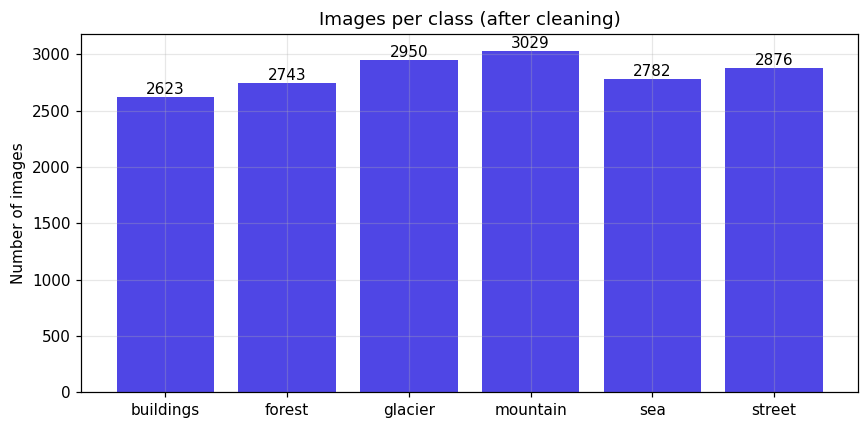

Imbalance ratio (max/min): 1.15


In [14]:
counts = df_clean["label"].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color="#4f46e5")
ax.bar_label(bars)
ax.set_title("Images per class (after cleaning)")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_distribution.png")
plt.show()

print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))


* **Observation:** After cleaning, the dataset holds 17,003 images across 6 classes. The imbalance ratio is 1.15 (mountain is largest, buildings smallest), so the classes are effectively balanced.
  
* **Decision:** No class weighting or resampling. The stratified split keeps the same class proportions in train, val 
and test. I will still report macro-F1 and per-class recall so a weak class cannot hide behind overall accuracy.

# Sample image grid (5 per class)

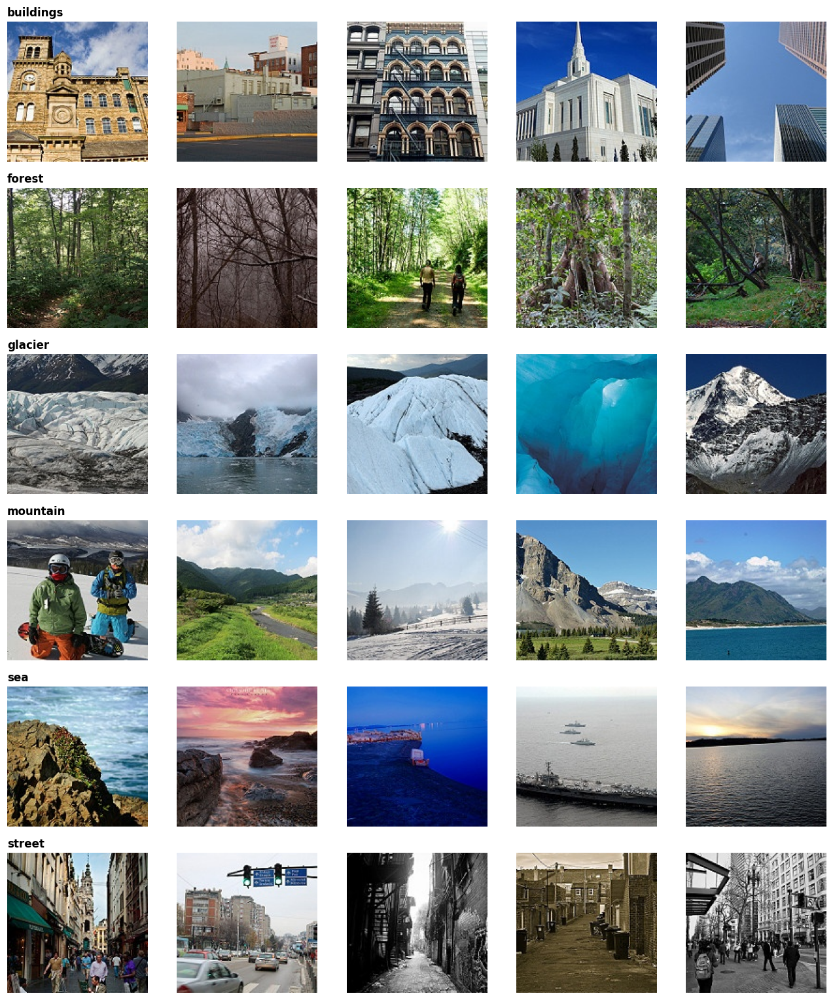

In [15]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 14))
for i, cls in enumerate(CLASSES):
    samples = df_clean[df_clean["label"] == cls].sample(5, random_state=SEED)
    for j, path in enumerate(samples["path"]):
        axes[i, j].imshow(Image.open(path).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/sample_grid.png")
plt.show()


* **Observation:** Classes are visually diverse inside (forests with hikers, mountains with snowboarders, sea with ships). Some boundaries are inherently ambiguous: glacier vs mountain (snow-covered peaks in both), mountain vs sea (a shoreline with mountains behind), and buildings vs street (streets contain buildings). Several street images are grayscale or sepia.

* **Decision:** Colour is not a reliable cue for every class, so augmentation uses only mild brightness and contrast changes and no hue shifts. No vertical flips, because scenes have a natural up direction (sky above). I expect the confusion matrix to concentrate on glacier/mountain and buildings/street, which I will test in the error analysis.


# Image dimension and aspect ratio distribution

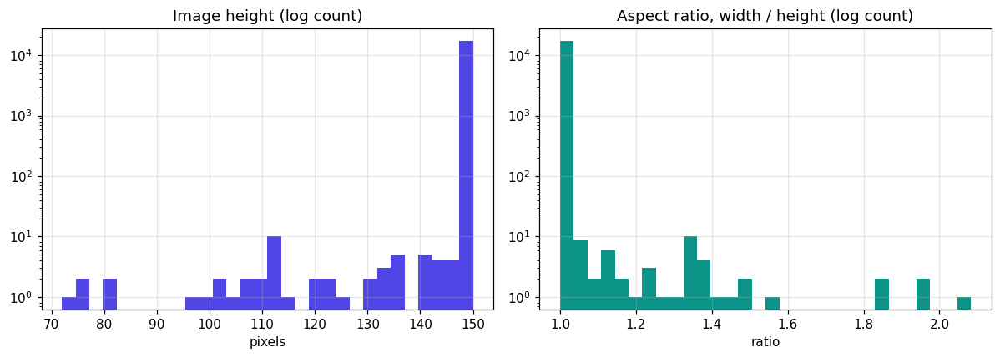

Width values: [150]
Non-150x150 images: 55
label
glacier      21
mountain     19
forest        9
sea           4
buildings     1
street        1


In [16]:

df_clean["aspect"] = df_clean["width"] / df_clean["height"]
odd = df_clean[(df_clean["width"] != 150) | (df_clean["height"] != 150)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df_clean["height"], bins=30, color="#4f46e5")
axes[0].set_yscale("log")
axes[0].set_title("Image height (log count)")
axes[0].set_xlabel("pixels")

axes[1].hist(df_clean["aspect"], bins=30, color="#0d9488")
axes[1].set_yscale("log")
axes[1].set_title("Aspect ratio, width / height (log count)")
axes[1].set_xlabel("ratio")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/dimensions_aspect.png")
plt.show()

print("Width values:", df_clean["width"].unique())
print("Non-150x150 images:", len(odd))
print(odd["label"].value_counts().to_string())


* **Observation:** Every image is 150 px wide. Only 55 images (0.32%) have a height below 150 px, down to 72 px, mostly glacier (21) and mountain (19). Aspect ratios are therefore 1.0 for almost the whole dataset.

* **Decision:** Resize all images to 224x224 with bilinear interpolation. This is the native input size of the candidate backbones (MobileNetV2, ResNet50, EfficientNetB0) and puts objects at a scale closer to what the ImageNet weights saw. Stretching the 55 non-square images is negligible. These images are kept.


# Train vs validation comparability

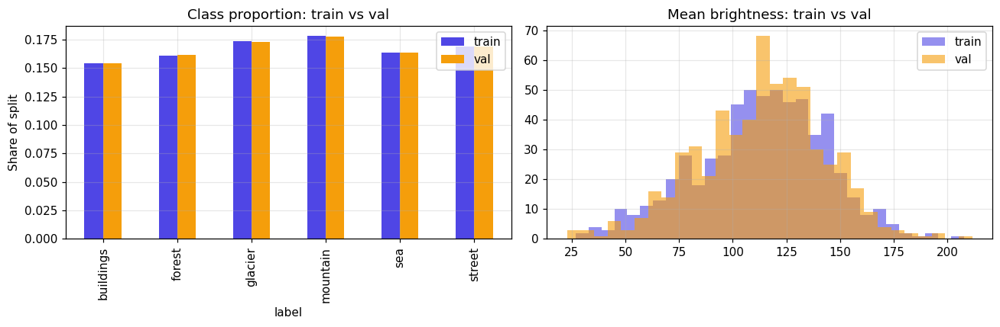

Mean brightness  train: 113.2 | val: 113.3


In [17]:
# Class proportions per split
props = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val":   val_df["label"].value_counts(normalize=True),
}).reindex(CLASSES)

# Mean brightness on a random sample of each split
def mean_brightness(paths):
    return [np.asarray(Image.open(p).convert("L")).mean() for p in paths]

b_train = mean_brightness(train_df["path"].sample(600, random_state=SEED))
b_val   = mean_brightness(val_df["path"].sample(600, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
props.plot.bar(ax=axes[0], color=["#4f46e5", "#f59e0b"])
axes[0].set_title("Class proportion: train vs val")
axes[0].set_ylabel("Share of split")
axes[1].hist(b_train, bins=30, alpha=0.6, label="train", color="#4f46e5")
axes[1].hist(b_val, bins=30, alpha=0.6, label="val", color="#f59e0b")
axes[1].set_title("Mean brightness: train vs val")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/train_val_comparison.png")
plt.show()

print("Mean brightness  train:", round(np.mean(b_train), 1), "| val:", round(np.mean(b_val), 1))


* **Observation:** Class proportions in train and validation are nearly identical, and mean brightness is 113.2 (train) vs 113.3 (val).

* **Conclusion:** The splits are comparable, so validation metrics should be a fair proxy for generalisation.


# Image size and augmentation (which is applied to the training set only) pipeline

In [18]:
from tensorflow.keras import layers

IMG_SIZE = 224

tf.keras.utils.set_random_seed(SEED)

# Works on raw 0-255 pixels. Backbone-specific normalisation is applied later, inside the model.
AUGMENTATIONS = {
    "Horizontal flip":   layers.RandomFlip("horizontal"),
    "Rotation (±11°)":   layers.RandomRotation((-0.03, 0.03), fill_mode="nearest"),
    "Zoom in (0-15%)":   layers.RandomZoom((-0.15, 0.0), fill_mode="nearest"),
    "Translation (5%)":  layers.RandomTranslation(0.05, 0.05, fill_mode="nearest"),
    "Brightness (±10%)": layers.RandomBrightness(0.10, value_range=(0, 255)),
    "Contrast (±20%)":   layers.RandomContrast(0.2),
}

data_augmentation = tf.keras.Sequential(list(AUGMENTATIONS.values()), name="data_augmentation")

# Load one image helper

In [19]:
def load_img(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype="float32")

def apply_aug(layer, x):
    out = layer(tf.expand_dims(x, 0), training=True)[0].numpy()
    return np.clip(out, 0, 255).astype("uint8")

# Augmented examples next to originals (each transform on its own, then combined)

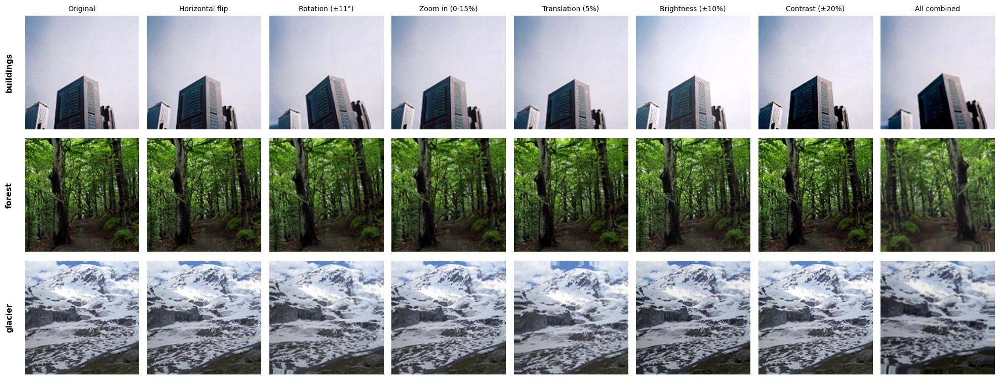

In [20]:
examples = train_df.groupby("label").sample(1, random_state=SEED).head(3)

fig, axes = plt.subplots(len(examples), 2 + len(AUGMENTATIONS), figsize=(18, 7))
col_titles = ["Original"] + list(AUGMENTATIONS.keys()) + ["All combined"]

for r, (_, row) in enumerate(examples.iterrows()):
    x = load_img(row["path"])
    images = [x.astype("uint8")]
    images += [apply_aug(layer, x) for layer in AUGMENTATIONS.values()]
    images += [apply_aug(data_augmentation, x)]
    for c, im in enumerate(images):
        axes[r, c].imshow(im)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(col_titles[c], fontsize=9)
    axes[r, 0].text(-0.1, 0.5, row["label"], transform=axes[r, 0].transAxes,
                    rotation=90, va="center", ha="right", fontweight="bold")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/augmentation_examples.png")
plt.show()

* **Observation:** Each transform changes the image in a visible, realistic way while the scene stays recognisable: flips, small rotations and shifts simulate different camera framing; brightness and contrast simulate different lighting. A first version produced two artifacts: reflected borders (fill_mode="reflect") created mirrored patterns, and ±20% brightness blew pale skies out to pure white. A second version still smeared edges when zooming out.

* **Decision (final):** Fill empty borders with the nearest pixel, zoom in only (0 to 15%, which never creates empty borders), translation 5%, rotation ±11°, brightness ±10%, contrast ±20%. No vertical flips and no hue shifts, as decided in the sample-grid analysis. Augmentation is applied to the training set only.

# Class index mapping

In [21]:
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
AUTOTUNE = tf.data.AUTOTUNE
print(CLASS_TO_IDX)

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


# tf.data pipeline with an in-RAM uint8 cache

In [22]:
def _load_and_resize(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")
    img = tf.cast(tf.round(img), tf.uint8)   # uint8 keeps the cache small (~2 GB for train)
    return img, label

def make_dataset(frame, training):
    paths  = frame["path"].values
    labels = frame["label"].map(CLASS_TO_IDX).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(_load_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()                                   # decode + resize once, reuse every epoch
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(GLOBAL_BATCH_SIZE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:                                      # augmentation on the TRAINING set only
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)  # built now, NOT evaluated until the very end

# Pipeline sanity check

In [23]:
x, y = next(iter(train_ds))
print("Train batch:", x.shape, y.shape, "| pixel range:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

xv, yv = next(iter(val_ds))
print("Val batch:  ", xv.shape, yv.shape, "| pixel range:", float(tf.reduce_min(xv)), "-", float(tf.reduce_max(xv)))
print("Steps per epoch:", len(train_ds), "| val steps:", len(val_ds))

Train batch: (64, 224, 224, 3) (64,) | pixel range: 0.0 - 255.0
Val batch:   (64, 224, 224, 3) (64,) | pixel range: 0.0 - 255.0
Steps per epoch: 186 | val steps: 40


* **Observation:** Batches have shape (64, 224, 224, 3) with integer labels, pixels in 0-255, 186 training steps and 40 validation steps per epoch. Augmentation is attached to the training dataset only. The test dataset is built but not evaluated until the end.

* **Decision:** Backbone-specific normalisation is applied inside the model, so the saved model accepts raw 0-255 images and the app needs no separate preprocessing code.

# Backbone-specific preprocessing layer (keeps the saved model self-contained)

In [24]:
from tensorflow.keras import applications as apps

@tf.keras.utils.register_keras_serializable(package="seker")
class BackbonePreprocess(layers.Layer):
    """Applies the exact preprocessing each pretrained backbone expects (input: raw 0-255 RGB)."""
    def __init__(self, kind, **kwargs):
        super().__init__(**kwargs)
        self.kind = kind
        self._fn = {
            "mobilenetv2":    apps.mobilenet_v2.preprocess_input,
            "resnet50":       apps.resnet50.preprocess_input,
            "efficientnetb0": apps.efficientnet.preprocess_input,
        }[kind]

    def call(self, x):
        return self._fn(x)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"kind": self.kind})
        return cfg

# Model builder (frozen backbone + custom head, built inside the multi-GPU scope)

In [25]:
CTORS = {
    "mobilenetv2":    apps.MobileNetV2,
    "resnet50":       apps.ResNet50,
    "efficientnetb0": apps.EfficientNetB0,
}

def build_model(kind, lr=1e-3):
    with strategy.scope():
        base = CTORS[kind](include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        base.trainable = False

        inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
        x = BackbonePreprocess(kind)(inputs)
        x = base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.4)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)

        model = tf.keras.Model(inputs, outputs, name=f"{kind}_classifier")
        model.compile(
            optimizer=tf.keras.optimizers.Adam(lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
    return model

# Callbacks (early stopping on val loss, checkpoint best weights, LR reduction)

In [26]:
MODEL_DIR = "/kaggle/working/models"
os.makedirs(MODEL_DIR, exist_ok=True)

def make_callbacks(tag):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/{tag}.keras", monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]

# Experiment 1 - train the head on each frozen backbone (identical settings)

In [28]:
import time, json

HEAD_EPOCHS = 15
histories, info = {}, {}

for kind in CTORS:
    print(f"\n===== {kind} =====")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(kind)
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                  callbacks=make_callbacks(f"{kind}_head"), verbose=2)
    histories[kind] = h.history
    info[kind] = {"params_M": round(model.count_params() / 1e6, 2),
                  "train_minutes": round((time.time() - t0) / 60, 1)}

with open("/kaggle/working/head_histories.json", "w") as f:
    json.dump(histories, f)


===== mobilenetv2 =====
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast 

E0000 00:00:1792073199.328601      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_classifier_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


186/186 - 89s - 478ms/step - accuracy: 0.8823 - loss: 0.3261 - val_accuracy: 0.9227 - val_loss: 0.2135 - learning_rate: 0.0010
Epoch 2/15
186/186 - 74s - 400ms/step - accuracy: 0.9192 - loss: 0.2227 - val_accuracy: 0.9267 - val_loss: 0.1922 - learning_rate: 0.0010
Epoch 3/15
186/186 - 72s - 390ms/step - accuracy: 0.9261 - loss: 0.1998 - val_accuracy: 0.9247 - val_loss: 0.1862 - learning_rate: 0.0010
Epoch 4/15
186/186 - 74s - 397ms/step - accuracy: 0.9309 - loss: 0.1851 - val_accuracy: 0.9294 - val_loss: 0.1890 - learning_rate: 0.0010
Epoch 5/15
186/186 - 72s - 389ms/step - accuracy: 0.9340 - loss: 0.1806 - val_accuracy: 0.9349 - val_loss: 0.1813 - learning_rate: 0.0010
Epoch 6/15
186/186 - 73s - 391ms/step - accuracy: 0.9407 - loss: 0.1632 - val_accuracy: 0.9333 - val_loss: 0.1745 - learning_rate: 0.0010
Epoch 7/15
186/186 - 71s - 384ms/step - accuracy: 0.9430 - loss: 0.1577 - val_accuracy: 0.9353 - val_loss: 0.1756 - learning_rate: 0.0010
Epoch 8/15
186/186 - 73s - 393ms/step - accur

# Compare the three backbones (validation data only, test set untouched)

In [30]:
rows = []
for kind, hist in histories.items():
    b = int(np.argmin(hist["val_loss"]))
    rows.append({
        "backbone": kind,
        "params_M": info[kind]["params_M"],
        "best_epoch": b + 1,
        "train_acc": round(hist["accuracy"][b], 4),
        "val_acc": round(hist["val_accuracy"][b], 4),
        "val_loss": round(hist["val_loss"][b], 4),
        "train_minutes": info[kind]["train_minutes"],
    })
comparison = pd.DataFrame(rows).set_index("backbone")
comparison

,params_M,best_epoch,train_acc,val_acc,val_loss,train_minutes
backbone,,,,,,
mobilenetv2,2.59,13,0.9403,0.9235,0.1987,18.1
resnet50,24.11,6,0.9340,0.9341,0.1698,13.3
efficientnetb0,4.38,11,0.9539,0.9337,0.1717,18.5


* **Observation:** With a frozen backbone and identical settings, ResNet50 and EfficientNetB0 both reach 93.5% validation accuracy; MobileNetV2 is lower at 92.5% and had not converged by epoch 15. ResNet50 has the lowest single-epoch val loss (0.1664) but its val loss fluctuates between epochs, whereas EfficientNetB0's is steadier (0.177-0.188 over epochs 6-13) with 4.4M parameters vs ResNet50's 24.1M. With 2,550 validation images, a 0.5-point difference is within noise. EfficientNetB0's train accuracy keeps rising (95.6%) while val accuracy plateaus (~93.2%), so the head begins to overfit after about epoch 9.

* **Decision:** Reject MobileNetV2 (lowest accuracy). Fine-tune both ResNet50 and EfficientNetB0 under identical settings, and choose the final model on validation results. The test set stays untouched.

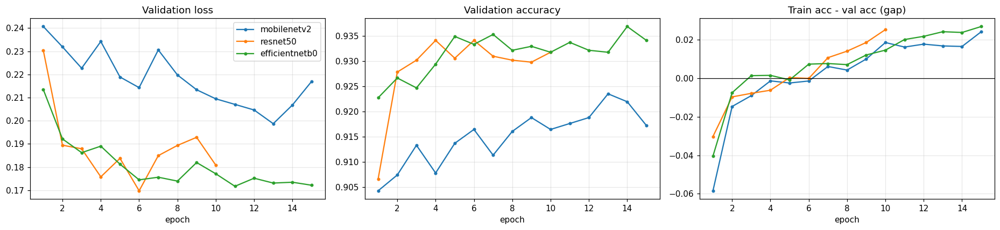

In [38]:
# 01-eda-and-preprocessing.ipynb  |  CELL 29: Validation curves and train/val gap for the three backbones

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for kind, h in histories.items():
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], marker="o", ms=3, label=kind)
    axes[1].plot(ep, h["val_accuracy"], marker="o", ms=3, label=kind)
    axes[2].plot(ep, np.array(h["accuracy"]) - np.array(h["val_accuracy"]), marker="o", ms=3, label=kind)
axes[0].set_title("Validation loss");        axes[0].set_xlabel("epoch")
axes[1].set_title("Validation accuracy");    axes[1].set_xlabel("epoch")
axes[2].set_title("Train acc - val acc (gap)"); axes[2].set_xlabel("epoch")
axes[2].axhline(0, color="k", lw=0.8)
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/backbone_comparison.png")
plt.show()

In [39]:
# 01-eda-and-preprocessing.ipynb  |  CELL 30: Fine-tuning setup (unfreeze top layers, keep BatchNorm frozen, low learning rate)

UNFREEZE_LAYERS = {"resnet50": 30, "efficientnetb0": 40}   # number of final backbone layers to unfreeze
FT_LR = 1e-4
FT_EPOCHS = 20

def load_for_finetuning(kind):
    with strategy.scope():
        model = tf.keras.models.load_model(f"{MODEL_DIR}/{kind}_head.keras")  # best head-stage weights
        base = next(l for l in model.layers if isinstance(l, tf.keras.Model))
        base.trainable = True
        for l in base.layers[:-UNFREEZE_LAYERS[kind]]:
            l.trainable = False
        for l in base.layers:                      # BatchNorm stays frozen: stable statistics with small batches
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
        model.compile(
            optimizer=tf.keras.optimizers.Adam(FT_LR),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
    return model

In [40]:
# 01-eda-and-preprocessing.ipynb  |  CELL 31: Experiment 2 - fine-tune both finalists (identical settings)

ft_histories, ft_info = {}, {}

for kind in UNFREEZE_LAYERS:
    print(f"\n===== fine-tuning {kind} =====")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = load_for_finetuning(kind)
    n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"Trainable parameters: {n_trainable / 1e6:.2f}M")
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
                  callbacks=make_callbacks(f"{kind}_finetuned"), verbose=2)
    ft_histories[kind] = h.history
    ft_info[kind] = {"trainable_M": round(n_trainable / 1e6, 2),
                     "train_minutes": round((time.time() - t0) / 60, 1)}

with open("/kaggle/working/finetune_histories.json", "w") as f:
    json.dump(ft_histories, f)


===== fine-tuning resnet50 =====
Trainable parameters: 14.95M
Epoch 1/20
INFO:tensorflow:Collective all_reduce tensors: 22 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
186/186 - 93s - 502ms/step - accuracy: 0.9281 - loss: 0.1943 - val_accuracy: 0.9329 - val_loss: 0.1939 - learning_rate: 1.0000e-04
Epoch 2/20
186/186 - 80s - 432ms/step - accuracy: 0.9435 - loss: 0.1525 - val_accuracy: 0.9361 - val_loss: 0.1927 - learning_rate: 1.0000e-04
Epoch 3/20
186/186 - 81s - 437ms/step - accuracy: 0.9501 - loss: 0.1297 - val_accuracy: 0.9384 - val_loss: 0.1854 - learning_rate: 1.0000e-04
Epoch 4/20
186/186 - 79s - 424ms/step - accuracy: 0.9609 - loss: 0.1076 - val_accuracy: 0.9373 - val_loss: 0.1858 - learning_rate: 1.0000e-04
Epoch 5/20
186/186 - 80s - 432ms/step - accuracy: 0.9642 - loss: 0.1015 - val_accuracy: 0.9369 - val_loss: 0.1947 - learning_rate: 1.0000e-04
Epoch 6/20
186/186 - 82s - 442ms/step - accuracy: 0.9745 - loss: 0

E0000 00:00:1792078489.317653      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_classifier_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


186/186 - 89s - 481ms/step - accuracy: 0.9514 - loss: 0.1315 - val_accuracy: 0.9384 - val_loss: 0.1719 - learning_rate: 1.0000e-04
Epoch 2/20
186/186 - 73s - 391ms/step - accuracy: 0.9583 - loss: 0.1123 - val_accuracy: 0.9392 - val_loss: 0.1731 - learning_rate: 1.0000e-04
Epoch 3/20
186/186 - 75s - 403ms/step - accuracy: 0.9650 - loss: 0.0951 - val_accuracy: 0.9392 - val_loss: 0.1696 - learning_rate: 1.0000e-04
Epoch 4/20
186/186 - 73s - 395ms/step - accuracy: 0.9688 - loss: 0.0840 - val_accuracy: 0.9404 - val_loss: 0.1777 - learning_rate: 1.0000e-04
Epoch 5/20
186/186 - 74s - 396ms/step - accuracy: 0.9716 - loss: 0.0764 - val_accuracy: 0.9404 - val_loss: 0.1786 - learning_rate: 1.0000e-04
Epoch 6/20
186/186 - 73s - 394ms/step - accuracy: 0.9759 - loss: 0.0651 - val_accuracy: 0.9412 - val_loss: 0.1794 - learning_rate: 5.0000e-05
Epoch 7/20
186/186 - 74s - 399ms/step - accuracy: 0.9782 - loss: 0.0594 - val_accuracy: 0.9416 - val_loss: 0.1793 - learning_rate: 5.0000e-05


In [34]:
print({k: len(v["val_loss"]) for k, v in ft_histories.items()})
print(os.listdir(MODEL_DIR))
print(os.path.exists("/kaggle/working/finetune_histories.json"))

{'resnet50': 7, 'efficientnetb0': 7}
['mobilenetv2_head.keras', 'resnet50_finetuned.keras', 'resnet50_head.keras', 'efficientnetb0_head.keras', 'efficientnetb0_finetuned.keras']
True


# Fresh download bundle (replaces the stale zip)

In [41]:
import shutil, glob, os
from IPython.display import FileLink, display

for z in glob.glob("/kaggle/working/*.zip"):      # remove the stale zip(s)
    os.remove(z)

shutil.make_archive("/tmp/seker_project04_outputs", "zip", "/kaggle/working")
shutil.move("/tmp/seker_project04_outputs.zip", "/kaggle/working/seker_project04_outputs.zip")

print("Model files:")
for f in sorted(os.listdir("/kaggle/working/models")):
    print(f"  {f}  {os.path.getsize('/kaggle/working/models/' + f) / 1e6:.0f} MB")
print(f"\nZip size: {os.path.getsize('/kaggle/working/seker_project04_outputs.zip') / 1e6:.0f} MB")
display(FileLink("/kaggle/working/seker_project04_outputs.zip"))

Model files:
  efficientnetb0_finetuned.keras  37 MB
  efficientnetb0_head.keras  21 MB
  mobilenetv2_head.keras  14 MB
  resnet50_finetuned.keras  217 MB
  resnet50_head.keras  101 MB

Zip size: 364 MB


/kaggle/working/seker_project04_outputs.zip

In [42]:
from IPython.display import FileLink, display
import os

zip_path = "/kaggle/working/seker_project04_outputs.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", os.path.getsize(zip_path) / (1024**2), "MB")

display(FileLink("seker_project04_outputs.zip"))

File exists: True
File size: 347.4206199645996 MB


/kaggle/working/seker_project04_outputs.zip

# Fine-tuned models: validation comparison and error analysis (test set untouched)

,best_epoch,train_acc,val_acc,val_loss
model,,,,
resnet50,6,0.9745,0.9451,0.1833
efficientnetb0,3,0.9650,0.9392,0.1696



=== resnet50 | val acc 0.9451 ===
              precision    recall  f1-score   support

   buildings      0.949     0.942     0.945       394
      forest      0.990     0.995     0.993       412
     glacier      0.923     0.894     0.908       442
    mountain      0.910     0.914     0.912       454
         sea      0.964     0.976     0.970       417
      street      0.938     0.956     0.947       431

    accuracy                          0.945      2550
   macro avg      0.946     0.946     0.946      2550
weighted avg      0.945     0.945     0.945      2550


=== efficientnetb0 | val acc 0.9392 ===
              precision    recall  f1-score   support

   buildings      0.922     0.934     0.928       394
      forest      0.988     0.998     0.993       412
     glacier      0.940     0.855     0.896       442
    mountain      0.885     0.936     0.910       454
         sea      0.962     0.978     0.970       417
      street      0.944     0.940     0.942       431

 

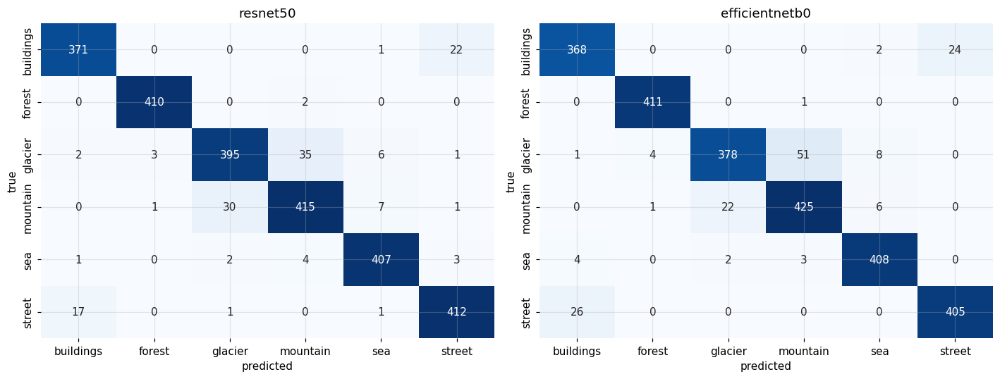

In [43]:
# 01-eda-and-preprocessing.ipynb  |  CELL 33: Fine-tuned comparison, per-class reports and confusion matrices (validation only)

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

rows = []
for kind, h in ft_histories.items():
    b = int(np.argmin(h["val_loss"]))
    rows.append({"model": kind, "best_epoch": b + 1,
                 "train_acc": round(h["accuracy"][b], 4),
                 "val_acc": round(h["val_accuracy"][b], 4),
                 "val_loss": round(h["val_loss"][b], 4)})
display(pd.DataFrame(rows).set_index("model"))

y_true = val_df["label"].map(CLASS_TO_IDX).values
probs = {}
for kind in UNFREEZE_LAYERS:
    m = tf.keras.models.load_model(f"{MODEL_DIR}/{kind}_finetuned.keras")
    probs[kind] = m.predict(val_ds, verbose=0)
    pred = probs[kind].argmax(1)
    print(f"\n=== {kind} | val acc {(pred == y_true).mean():.4f} ===")
    print(classification_report(y_true, pred, target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (kind, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_true, p.argmax(1))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(kind); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_val.png")
plt.show()

* **Observation:** On validation data ResNet50 (94.5% accuracy, macro-F1 0.946) outperforms EfficientNetB0 (93.9%, 0.940). Both classify forest (F1 0.99) and sea (0.97) almost perfectly, and both struggle with the same two ambiguous boundaries identified in the sample grid: glacier/mountain and buildings/street. ResNet50 makes fewer errors in both pairs (glacier/mountain 65 vs 73; buildings/street 39 vs 50) and has higher glacier recall (0.894 vs 0.855). EfficientNetB0 has a lower validation loss (0.1696 vs 0.1833) and is far smaller. The accuracy gap (~0.6 points, about 15 images) is small but consistent across metrics.

* **Decision:** ResNet50 is the final model, chosen on validation data only. Its higher validation loss may indicate overconfident probabilities, which we test and correct with temperature scaling fitted on the validation set.

# Confidence calibration (temperature scaling, fitted on validation data only)

Temperature T = 1.677   (T > 1 means the model was overconfident)
Val NLL : 0.1833 -> 0.1569
Val ECE : 0.0232 -> 0.0078
Predictions unchanged: True


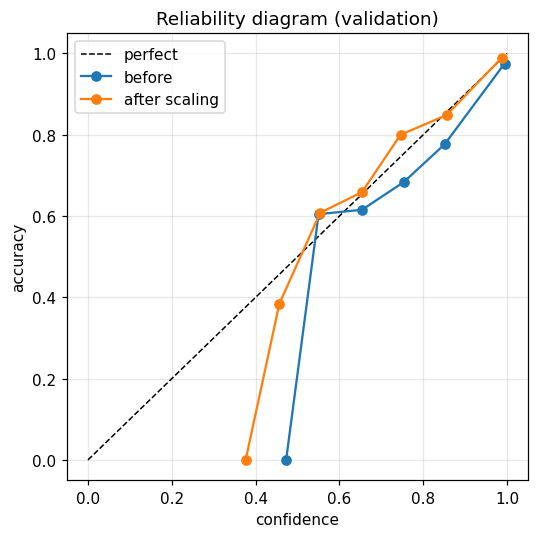

In [44]:
# Calibration check and temperature scaling for the final model (ResNet50)

from scipy.optimize import minimize_scalar

def to_logp(p):
    return np.log(np.clip(p, 1e-12, 1.0))

def scaled(logp, T):
    z = logp / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def nll(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def ece(p, y, bins=15):
    conf, correct = p.max(1), (p.argmax(1) == y)
    edges, total = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(total)

def reliability(p, y, bins=10):
    conf, correct = p.max(1), (p.argmax(1) == y)
    edges, xs, ys = np.linspace(0, 1, bins + 1), [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return xs, ys

# probs["resnet50"] and y_true (validation) are still in memory from CELL 33
p_val = probs["resnet50"]
lp_val = to_logp(p_val)
res = minimize_scalar(lambda T: nll(scaled(lp_val, T), y_true), bounds=(0.5, 5.0), method="bounded")
TEMPERATURE = float(res.x)
p_val_cal = scaled(lp_val, TEMPERATURE)

print(f"Temperature T = {TEMPERATURE:.3f}   (T > 1 means the model was overconfident)")
print(f"Val NLL : {nll(p_val, y_true):.4f} -> {nll(p_val_cal, y_true):.4f}")
print(f"Val ECE : {ece(p_val, y_true):.4f} -> {ece(p_val_cal, y_true):.4f}")
print("Predictions unchanged:", bool((p_val.argmax(1) == p_val_cal.argmax(1)).all()))

with open("/kaggle/working/temperature.json", "w") as f:
    json.dump({"temperature": TEMPERATURE, "model": "resnet50_finetuned"}, f)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
for name, p in [("before", p_val), ("after scaling", p_val_cal)]:
    xs, ys = reliability(p, y_true)
    ax.plot(xs, ys, marker="o", label=name)
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title("Reliability diagram (validation)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/reliability_val.png")
plt.show()

# Final evaluation on the held-out test set (used once)

TEST accuracy : 0.9428
TEST macro-F1 : 0.9437

              precision    recall  f1-score   support

   buildings      0.947     0.952     0.949       393
      forest      0.981     0.990     0.985       411
     glacier      0.904     0.892     0.898       443
    mountain      0.921     0.895     0.907       455
         sea      0.967     0.974     0.970       417
      street      0.941     0.963     0.952       432

    accuracy                          0.943      2551
   macro avg      0.943     0.944     0.944      2551
weighted avg      0.942     0.943     0.943      2551

Test NLL : 0.2041 -> 0.1670 (after temperature scaling)
Test ECE : 0.0284 -> 0.0135 (after temperature scaling)


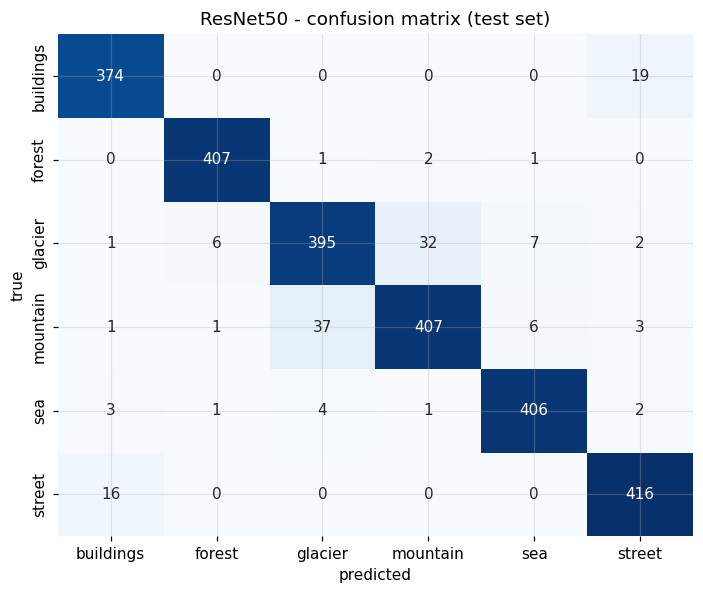

In [45]:
# 01-eda-and-preprocessing.ipynb  |  CELL 35: Final test-set evaluation of ResNet50 (run ONCE)

from sklearn.metrics import accuracy_score, f1_score

y_test = test_df["label"].map(CLASS_TO_IDX).values
final_model = tf.keras.models.load_model(f"{MODEL_DIR}/resnet50_finetuned.keras")

p_test_raw = final_model.predict(test_ds, verbose=0)
p_test = scaled(to_logp(p_test_raw), TEMPERATURE)
pred_test = p_test.argmax(1)

print(f"TEST accuracy : {accuracy_score(y_test, pred_test):.4f}")
print(f"TEST macro-F1 : {f1_score(y_test, pred_test, average='macro'):.4f}\n")
print(classification_report(y_test, pred_test, target_names=CLASSES, digits=3))
print(f"Test NLL : {nll(p_test_raw, y_test):.4f} -> {nll(p_test, y_test):.4f} (after temperature scaling)")
print(f"Test ECE : {ece(p_test_raw, y_test):.4f} -> {ece(p_test, y_test):.4f} (after temperature scaling)")

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title("ResNet50 - confusion matrix (test set)")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_test.png")
plt.show()

**Observation:** On the untouched test set (2551 images) ResNet50 reaches 94.28% accuracy and 0.9437 macro F1, matching its validation result (94.5%, 0.946). This agreement shows the model selection did not overfit the validation set. Forest (F1 0.985) and sea (0.970) are the strongest classes. Glacier (F1 0.898, recall 0.892) and mountain (F1 0.907, recall 0.895) are the weakest, followed by buildings (0.949) and street (0.952). Temperature scaling (T = 1.677, fitted on validation only) improved calibration on the test set without changing any prediction: NLL fell from 0.2041 to 0.1670 and ECE from 0.0284 to 0.0135. Confidence scores can therefore be read as probabilities with reasonable reliability.

# Error analysis: misclassified test images

Misclassified: 146 of 2551

Most common confusions (true -> predicted):
mountain -> glacier    37
glacier -> mountain    32
buildings -> street    19
street -> buildings    16
glacier -> sea          7
mountain -> sea         6
glacier -> forest       6
sea -> glacier          4


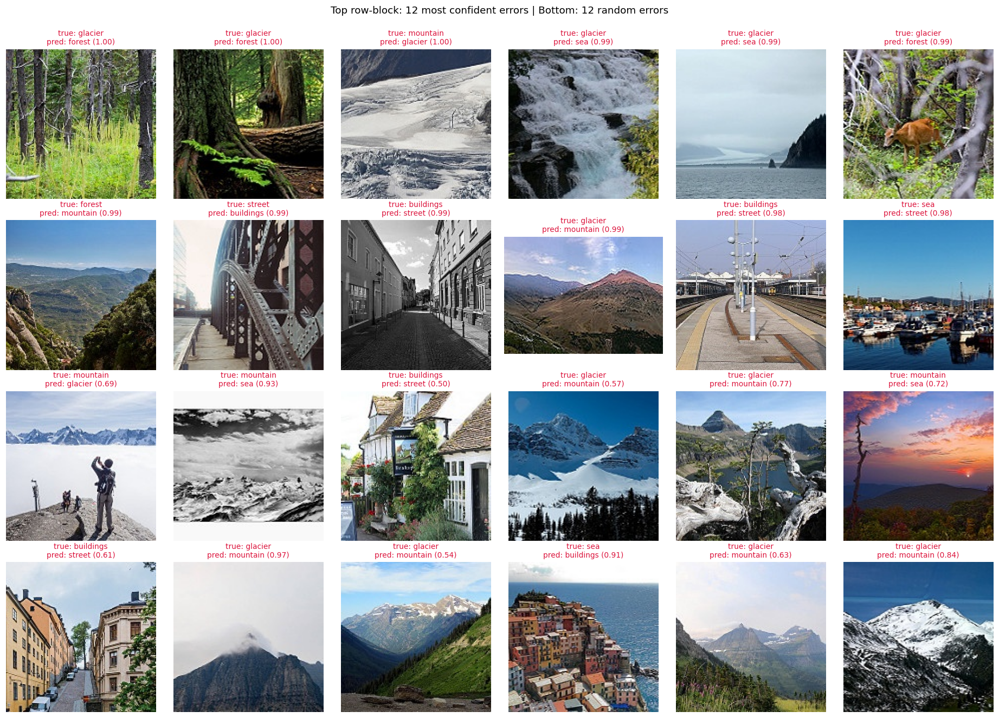

In [46]:
# 01-eda-and-preprocessing.ipynb  |  CELL 36: Misclassified test images (most confident errors, then random errors)

conf_test = p_test.max(1)
wrong = np.where(pred_test != y_test)[0]
print(f"Misclassified: {len(wrong)} of {len(y_test)}")

pairs = pd.Series([f"{CLASSES[y_test[i]]} -> {CLASSES[pred_test[i]]}" for i in wrong]).value_counts()
print("\nMost common confusions (true -> predicted):")
print(pairs.head(8).to_string())

confident = wrong[np.argsort(-conf_test[wrong])][:12]
rest = np.setdiff1d(wrong, confident)
rng = np.random.default_rng(SEED)
random_wrong = rng.choice(rest, size=min(12, len(rest)), replace=False)
show = list(confident) + list(random_wrong)

fig, axes = plt.subplots(4, 6, figsize=(17, 12))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(Image.open(test_df["path"][i]).convert("RGB"))
    ax.set_title(f"true: {CLASSES[y_test[i]]}\npred: {CLASSES[pred_test[i]]} ({conf_test[i]:.2f})",
                 fontsize=9, color="crimson")
    ax.axis("off")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.suptitle("Top row-block: 12 most confident errors | Bottom: 12 random errors", y=1.0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/misclassified_test.png")
plt.show()

**Observation:** The model made 146 errors out of 2551 images. Two confusion pairs account for most of them: mountain to glacier (37) and glacier to mountain (32), 69 errors in total, then buildings to street (19) and street to buildings (16), 35 errors. Together these four directions explain about 71% of all errors.

**Failure causes (from the misclassified image grid):**
* **Overlapping classes.** Snow covered peaks appear under both mountain and glacier, and rocky, snow free terrain appears under glacier. The label depends on a judgement that the pixels do not settle. Several of these errors are made at 0.99 confidence, which points to ambiguous labels rather than a model weakness.
* **Scene content versus label.** Several glacier images are mostly trees, a waterfall or a coastline and were predicted as forest or sea. A glacier labelled image of a forest with a small deer was predicted as forest at 0.99 confidence. The model follows the dominant object in the frame.
* **Similar structures.** A street between buildings, a railway platform, a steel bridge and a harbour with houses can legitimately be called buildings or street (or sea in the harbour case).
* **Image quality.** Grayscale and low contrast images (for example a black and white mountain predicted as sea) also appear among the errors.
* **Resolution.** The images are small (about 150 pixels per side originally), so fine texture that separates ice from rock is limited.

**Pattern in confidence:** Wrong predictions have a mean confidence of 0.722, compared with 0.957 for correct ones. The wrong but confident cases are mostly the ambiguous or mislabelled ones described above. Many of the low confidence errors (0.50 to 0.70) are borderline mountain scenes, which a confidence threshold can flag.

# Confidence threshold: coverage versus accuracy (test set, no model changes)

,coverage,accuracy_on_answered,sent_to_uncertain,errors_caught,errors_left
threshold,,,,,
0.50,0.9926,0.9467,19,11,135
0.60,0.9675,0.9599,83,47,99
0.70,0.9357,0.9690,164,72,74
0.80,0.8981,0.9756,260,90,56
0.90,0.8287,0.9825,437,109,37
0.95,0.7507,0.9880,636,123,23


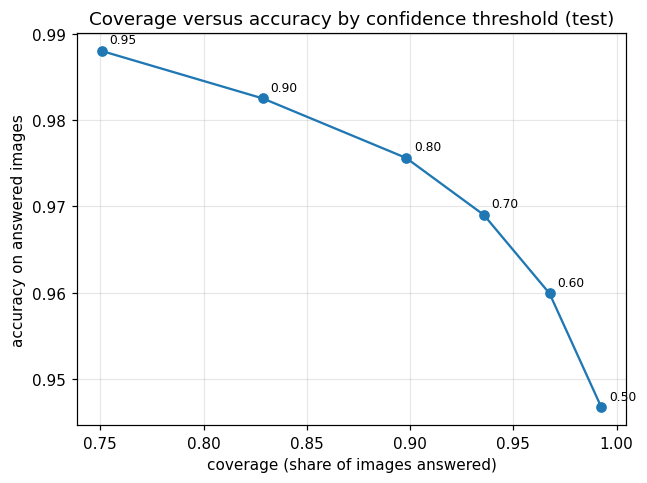

Mean confidence, correct : 0.957
Mean confidence, wrong   : 0.722


In [47]:
# CELL 37: Coverage versus accuracy for an "uncertain" threshold

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
is_wrong = pred_test != y_test
rows = []
for t in thresholds:
    keep = conf_test >= t
    rows.append({
        "threshold": t,
        "coverage": round(float(keep.mean()), 4),
        "accuracy_on_answered": round(float((pred_test[keep] == y_test[keep]).mean()), 4),
        "sent_to_uncertain": int((~keep).sum()),
        "errors_caught": int((is_wrong & ~keep).sum()),
        "errors_left": int((is_wrong & keep).sum()),
    })
cov_df = pd.DataFrame(rows).set_index("threshold")
display(cov_df)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(cov_df["coverage"], cov_df["accuracy_on_answered"], marker="o")
for t, r in cov_df.iterrows():
    ax.annotate(f"{t:.2f}", (r["coverage"], r["accuracy_on_answered"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("coverage (share of images answered)")
ax.set_ylabel("accuracy on answered images")
ax.set_title("Coverage versus accuracy by confidence threshold (test)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/coverage_accuracy_test.png")
plt.show()

# Average confidence for correct versus wrong predictions
print(f"Mean confidence, correct : {conf_test[~is_wrong].mean():.3f}")
print(f"Mean confidence, wrong   : {conf_test[is_wrong].mean():.3f}")

**Observation:** Confidence is informative: wrong predictions average 0.722 against 0.957 for correct ones. Raising the threshold trades coverage for accuracy. At 0.70 the app answers 93.6% of images with 96.9% accuracy (baseline 94.3%), sending 164 images to "uncertain", of which 72 are real errors (49% of all errors). At 0.90 accuracy on answered images is 98.3% but 17% of images are rejected. At 0.95 accuracy is 98.8% with 25% rejected.

**Decision:** The app uses a threshold of 0.70 and shows "uncertain, please review" below it, while still displaying the top predictions. It removes about half of the errors for a loss of 6.4% coverage. Users who need higher accuracy can raise the threshold. Limitation: the threshold was inspected on the test set, so the 96.9% figure is slightly optimistic. It should be confirmed on fresh data.

# Export the inference package for the app

In [48]:
# CELL 38: Export inference model (no optimizer state), config, and a download bundle

import shutil, os
from IPython.display import FileLink

EXPORT_DIR = "/kaggle/working/export"
os.makedirs(EXPORT_DIR, exist_ok=True)

# compile=False drops the optimizer, so the saved file is much smaller
infer_model = tf.keras.models.load_model(f"{MODEL_DIR}/resnet50_finetuned.keras", compile=False)
infer_model.save(f"{EXPORT_DIR}/resnet50_inference.keras")

config = {
    "model_file": "resnet50_inference.keras",
    "classes": CLASSES,
    "image_size": IMG_SIZE,
    "resize_method": "bilinear",
    "input_range": "raw 0 to 255 RGB, preprocessing is inside the model",
    "temperature": TEMPERATURE,
    "uncertain_threshold": 0.70,
    "test_accuracy": round(float(accuracy_score(y_test, pred_test)), 4),
    "test_macro_f1": round(float(f1_score(y_test, pred_test, average="macro")), 4),
}
with open(f"{EXPORT_DIR}/model_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Sanity check: reloaded inference model must reproduce the notebook predictions
reloaded = tf.keras.models.load_model(f"{EXPORT_DIR}/resnet50_inference.keras")
xb, yb = next(iter(test_ds))
p_chk = reloaded.predict(xb, verbose=0)
n = len(p_chk)
print("Max probability difference vs earlier run:", float(np.abs(p_chk - p_test_raw[:n]).max()))
print("Same predicted classes:", bool((p_chk.argmax(1) == p_test_raw[:n].argmax(1)).all()))

size_mb = os.path.getsize(f"{EXPORT_DIR}/resnet50_inference.keras") / 1e6
print(f"Inference model size: {size_mb:.1f} MB")

# Bundle: inference model, config, temperature, all figures
shutil.copy("/kaggle/working/temperature.json", EXPORT_DIR)
shutil.copytree(FIG_DIR, f"{EXPORT_DIR}/figures", dirs_exist_ok=True)
shutil.make_archive("/kaggle/working/seker_project04_final", "zip", EXPORT_DIR)
display(FileLink("seker_project04_final.zip"))

I0000 00:00:1792080315.585318     137 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Max probability difference vs earlier run: 1.2218952178955078e-06
Same predicted classes: True
Inference model size: 97.1 MB


/kaggle/working/seker_project04_final.zip

**Observation:** The inference model was exported without optimizer state (97.1 MB, down from 217 MB). Reloading it reproduces the earlier test predictions (maximum probability difference 1.2e-06, identical classes), so the app will behave exactly like the notebook. The package contains the model, `model_config.json` (classes, image size, temperature 1.677, threshold 0.70), `temperature.json` and all figures. Preprocessing is built into the model, so the app only needs to open the image as RGB, resize to 224x224 bilinear and pass raw 0 to 255 pixel values.

# Fine tuning summary and full training configuration

,epochs_run,best_epoch,train_acc_at_best,val_acc_at_best,train_loss_at_best,val_loss_at_best,final_train_acc,final_val_acc
model,,,,,,,,
resnet50,10,6,0.9745,0.9451,0.0677,0.1833,0.9913,0.9451
efficientnetb0,7,3,0.9650,0.9392,0.0951,0.1696,0.9782,0.9416


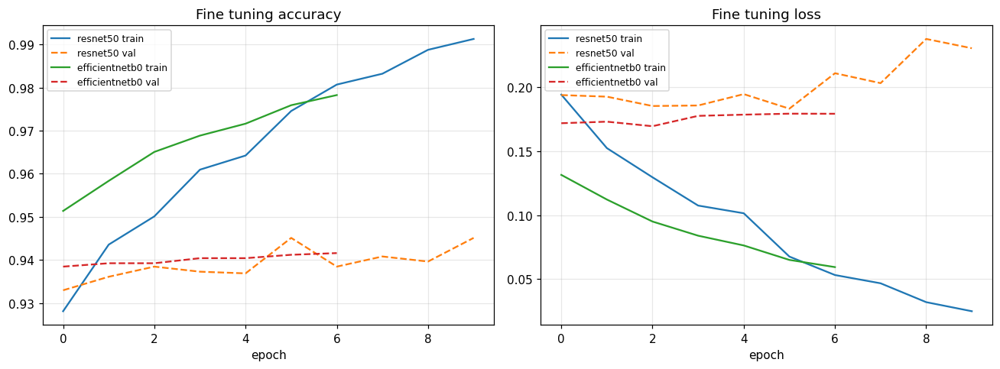

Loss: sparse_categorical_crossentropy
Optimizer: Adam | head LR 1e-3 | fine tune LR 0.0001
Unfrozen layers: {'resnet50': 30, 'efficientnetb0': 40} | BatchNorm frozen
Head epochs max 15 | fine tune epochs max 20
Global batch size: 64 | image size: 224 | seed: 42
Callbacks: EarlyStopping(val_loss, patience 4, restore best), ModelCheckpoint(best val_loss), ReduceLROnPlateau(factor 0.5, patience 2)


In [49]:
summary = []
for kind, h in ft_histories.items():
    best = int(np.argmin(h["val_loss"]))
    summary.append({
        "model": kind,
        "epochs_run": len(h["val_loss"]),
        "best_epoch": best + 1,
        "train_acc_at_best": round(h["accuracy"][best], 4),
        "val_acc_at_best": round(h["val_accuracy"][best], 4),
        "train_loss_at_best": round(h["loss"][best], 4),
        "val_loss_at_best": round(h["val_loss"][best], 4),
        "final_train_acc": round(h["accuracy"][-1], 4),
        "final_val_acc": round(h["val_accuracy"][-1], 4),
    })
display(pd.DataFrame(summary).set_index("model"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for kind, h in ft_histories.items():
    axes[0].plot(h["accuracy"], label=f"{kind} train")
    axes[0].plot(h["val_accuracy"], linestyle="--", label=f"{kind} val")
    axes[1].plot(h["loss"], label=f"{kind} train")
    axes[1].plot(h["val_loss"], linestyle="--", label=f"{kind} val")
axes[0].set_title("Fine tuning accuracy"); axes[1].set_title("Fine tuning loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/finetune_curves.png")
plt.show()

print("Loss:", final_model.loss)
print("Optimizer: Adam | head LR 1e-3 | fine tune LR", FT_LR)
print("Unfrozen layers:", UNFREEZE_LAYERS, "| BatchNorm frozen")
print("Head epochs max 15 | fine tune epochs max", FT_EPOCHS)
print("Global batch size:", GLOBAL_BATCH_SIZE, "| image size:", IMG_SIZE, "| seed:", SEED)
print("Callbacks: EarlyStopping(val_loss, patience 4, restore best), ModelCheckpoint(best val_loss), ReduceLROnPlateau(factor 0.5, patience 2)")

**Full training configuration**
* **Data:** Intel Image Classification, 6 classes, 17,003 images after cleaning, stratified split 70/15/15 (11,902 train, 2,550 validation, 2,551 test), seed 42
* **Input:** 224x224 RGB, bilinear resize, raw 0 to 255 values, backbone specific preprocessing layer inside the model
* **Augmentation (train only):** horizontal flips, rotation up to 11 degrees, translation 5%, zoom in 0 to 15%, brightness 10%, contrast 20%, nearest pixel fill, no vertical flips, no hue shifts
* **Architecture:** pretrained ImageNet backbone, global average pooling, Dense 256 with ReLU, Dropout 0.4, Dense 6 with softmax
* **Loss and optimiser:** sparse categorical crossentropy, Adam
* **Stage 1 (head only):** backbone frozen, learning rate 1e-3, up to 15 epochs
* **Stage 2 (fine tuning):** last 30 backbone layers unfrozen for ResNet50 (40 for EfficientNetB0), BatchNorm layers kept frozen, learning rate 1e-4, up to 20 epochs
* **Batch size:** 64 (32 per GPU on 2 T4 GPUs)
* **Callbacks:** EarlyStopping on validation loss (patience 4, restore best weights), ModelCheckpoint on best validation loss, ReduceLROnPlateau (factor 0.5, patience 2, minimum 1e-6)
* **Final model:** ResNet50 fine tuned, temperature scaling T = 1.677 fitted on validation data